In [1]:
import os
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
#from langchain.chains import LLMChain
from langchain_core.tools import Tool
from langchain_classic.agents import initialize_agent, AgentType
from langchain_classic.memory import ConversationBufferMemory
#from langchain_community.memory import ConversationBufferMemory


# 🔐 Load API keys
load_dotenv(".env")
google_api_key=os.getenv("GOOGLE_API_KEY")

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite"
)

# Simple QA tool (LLMChain)
qa_prompt = ChatPromptTemplate.from_template("Answer clearly: {question}")
qa_chain = qa_prompt | llm
qa_tool = Tool(
    name="Simple_QA",
    func=lambda question: qa_chain.invoke({"question": question}), 
    description="Answer factual questions clearly"
)



![Model Diagram](memory.png)

In [2]:
#https://python.langchain.com/api_reference/langchain/memory.html?utm_source=chatgpt.com

In [3]:
#!pip install -U langchain-classic

#                  from langchain.memory import ConversationBufferMemory no longer exists


In [4]:
#🧠 1. ConversationBufferMemory
#                  from langchain.memory import ConversationBufferMemory no longer exists

from langchain_classic.memory import ConversationBufferMemory

# Memory (stores chat history)
memory = ConversationBufferMemory(memory_key="chat_history", return_messages=True,handle_parsing_errors=True)

# Agent with tool + memory
agent = initialize_agent(
    tools=[qa_tool],
    llm=llm,
    agent=AgentType.CONVERSATIONAL_REACT_DESCRIPTION,# ZERO_SHOT_REACT_DESCRIPTION
    verbose=True,
    memory=memory,
    handle_parsing_errors=True
)

# Run multiple interactions
print("1️⃣ First Question")
res1 = agent.run("What is LangChain?")
print("\nAnswer:", res1)

print("\n2️⃣ Follow-up Question")
res2 = agent.run("Who created it?")
print("\nAnswer:", res2)

print("\n3️⃣ Ask again about previous topic")
res3 = agent.run("Explain it simply again.")
print("\nAnswer:", res3)

#print(memory.chat_memory.messages)

for msg in memory.chat_memory.messages:
    print(f"{msg.type.upper()}: {msg.content}")

C:\Users\user\AppData\Local\Temp\ipykernel_7404\1701795214.py:7: LangChainDeprecationWarning: The class `ConversationBufferMemory` was deprecated in LangChain 0.3.1 and will be removed in 2.0.0. Use `langchain.agents.create_agent` instead. For agents that need to remember prior interactions, use `create_agent` with checkpointing or the `Store` API. See https://docs.langchain.com/oss/python/langchain/short-term-memory and https://docs.langchain.com/oss/python/langchain/long-term-memory
  memory = ConversationBufferMemory(memory_key="chat_history", return_messages=True,handle_parsing_errors=True)
C:\Users\user\anaconda3\envs\W18_Langchain\Lib\site-packages\pydantic\main.py:263: LangChainDeprecationWarning: The class `InMemoryChatMessageHistory` was deprecated in LangChain 1.6.4 and will be removed in 2.0.0 See the short-term memory documentation for recommended alternatives: https://docs.langchain.com/oss/python/langchain/short-term-memory
  validated_self = self.__pydantic_validator__.v

1️⃣ First Question


> Entering new AgentExecutor chain...
```
Thought: Do I need to use a tool? Yes
Action: Simple_QA
Action Input: What is LangChain?
Observation: content=[{'type': 'text', 'text': '**LangChain** is an open-source development framework designed to make it easier to build applications using Large Language Models (LLMs) like GPT-4. \n\nThink of it as a toolkit or "glue" that connects LLMs to other data sources and computational tools. \n\nHere is what it helps developers do:\n\n1. **Connect to Data:** It allows LLMs to read and search through external data—such as PDFs, databases, websites, and private company files—that the model wasn\'t originally trained on.\n2. **Chain Actions Together:** It lets you create complex workflows where the output of one LLM call becomes the input for the next, or for another tool (like a calculator or API).\n3. **Add Memory:** It helps chatbots and agents remember past conversations so they can have context-aware dialogues. \n\nIn short,

In [5]:
#2)ConversationBufferWindowMemory

#from langchain.memory import ConversationBufferWindowMemory
from langchain_classic.agents import initialize_agent, AgentType
from langchain_classic.memory import ConversationBufferWindowMemory

memory = ConversationBufferWindowMemory(k=3,memory_key="chat_history")   # K is N of last conversation can save

agent = initialize_agent(
    tools=[qa_tool],
    llm=llm,
    agent=AgentType.CONVERSATIONAL_REACT_DESCRIPTION,
    verbose=True,
    memory=memory
)

# Run multiple interactions
print("1️⃣ First Question")
res1 = agent.run("What is LangChain?")
print("\nAnswer:", res1)

print("\n2️⃣ Follow-up Question")
res2 = agent.run("Who created it?")
print("\nAnswer:", res2)

print("\n3️⃣ Ask again about previous topic")
res3 = agent.run("Explain it simply again.")
print("\nAnswer:", res3)

for msg in memory.chat_memory.messages:
    print(f"{msg.type.upper()}: {msg.content}")

1️⃣ First Question


> Entering new AgentExecutor chain...


C:\Users\user\AppData\Local\Temp\ipykernel_7404\756145978.py:7: LangChainDeprecationWarning: The class `ConversationBufferWindowMemory` was deprecated in LangChain 0.3.1 and will be removed in 2.0.0. Use `langchain.agents.create_agent` instead. For agents that need to remember prior interactions, use `create_agent` with checkpointing or the `Store` API. See https://docs.langchain.com/oss/python/langchain/short-term-memory and https://docs.langchain.com/oss/python/langchain/long-term-memory
  memory = ConversationBufferWindowMemory(k=3,memory_key="chat_history")   # K is N of last conversation can save


Thought: Do I need to use a tool? Yes
Action: Simple_QA
Action Input: What is LangChain?
Observation: content=[{'type': 'text', 'text': '**LangChain** is an open-source development framework designed to build applications powered by Large Language Models (LLMs) like GPT-4. \n\nThink of it as the "glue" or a software toolkit that connects LLMs to external data sources, memory, and tools, allowing them to do more than just generate text.\n\n### Key Things LangChain Does:\n1. **Connects Data (Retrieval-Augmented Generation / RAG):** It allows you to feed your own private documents (PDFs, databases, websites) to an LLM so it can answer questions based on your specific data.\n2. **Creates Chains & Workflows:** It lets you link multiple steps together. For example: *Step 1:* Take user input $\\rightarrow$ *Step 2:* Search a database $\\rightarrow$ *Step 3:* Summarize the findings $\\rightarrow$ *Step 4:* Output the result.\n3. **Adds Memory:** Standard LLMs forget past conversations. LangCha

#                  from langchain.memory import ConversationSummaryMemory no longer exists


In [6]:
#🧠 3. ConversationSummaryMemory
#from langchain.memory import ConversationSummaryMemory
from langchain_classic.memory import ConversationSummaryMemory
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate

llm = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite"
)

memory = ConversationSummaryMemory(llm=llm,memory_key="chat_history")
# Agent with tool + memory
agent = initialize_agent(
    tools=[qa_tool],
    llm=llm,
    agent=AgentType.CONVERSATIONAL_REACT_DESCRIPTION,
    verbose=True,
    memory=memory
)


# Run multiple interactions
print("1️⃣ First Question")
res1 = agent.run("What is LangChain?")
print("\nAnswer:", res1)

print("\n2️⃣ Follow-up Question")
res2 = agent.run("Who created it?")
print("\nAnswer:", res2)

print("\n3️⃣ Ask again about previous topic")
res3 = agent.run("Explain it simply again.")
print("\nAnswer:", res3)

for msg in memory.chat_memory.messages:
    print(f"{msg.type.upper()}: {msg.content}")

C:\Users\user\AppData\Local\Temp\ipykernel_7404\2084509416.py:11: LangChainDeprecationWarning: The class `ConversationSummaryMemory` was deprecated in LangChain 0.3.1 and will be removed in 2.0.0. Use `langchain.agents.create_agent` instead. For agents that need to remember prior interactions, use `create_agent` with checkpointing or the `Store` API. See https://docs.langchain.com/oss/python/langchain/short-term-memory and https://docs.langchain.com/oss/python/langchain/long-term-memory
  memory = ConversationSummaryMemory(llm=llm,memory_key="chat_history")


1️⃣ First Question


> Entering new AgentExecutor chain...
Thought: Do I need to use a tool? Yes
Action: Simple_QA
Action Input: What is LangChain?
Observation: content=[{'type': 'text', 'text': '**LangChain** is an open-source development framework designed to build applications powered by Large Language Models (LLMs) like GPT-4. \n\nThink of it as a **toolkit and glue** that connects LLMs to external data sources, memory, and other software tools, making it easier to build complex AI applications beyond simple chat.\n\n### Key Things LangChain Lets You Do:\n1. **Connect to Data (Retrieval-Augmented Generation / RAG):** Allow LLMs to read, search, and answer questions based on your private documents (PDFs, databases, websites).\n2. **Add Memory:** Give chatbots the ability to remember past conversations across multiple turns.\n3. **Create Agents:** Allow LLMs to make decisions, use search engines, run code, and execute tasks autonomously based on user input.\n4. **Chain Operations:** 

In [7]:
#!pip install faiss-cpu

In [8]:
#from langchain.memory import VectorStoreRetrieverMemory
from langchain_classic.memory import VectorStoreRetrieverMemory
#from langchain.vectorstores import FAISS
from langchain_community.vectorstores import FAISS
from langchain_google_genai import GoogleGenerativeAIEmbeddings

embedding = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001")

retriever = FAISS.from_texts(
    ["initial memory"],
    embedding
).as_retriever()


memory = VectorStoreRetrieverMemory(retriever=retriever,memory_key="chat_history")
# Agent with tool + memory
agent = initialize_agent(
    tools=[qa_tool],
    llm=llm,
    agent=AgentType.CONVERSATIONAL_REACT_DESCRIPTION,
    verbose=True,
    memory=memory
)

# Run multiple interactions
print("1️⃣ First Question")
res1 = agent.run("What is LangChain?")
print("\nAnswer:", res1)

print("\n2️⃣ Follow-up Question")
res2 = agent.run("Who created it?")
print("\nAnswer:", res2)

print("\n3️⃣ Ask again about previous topic")
res3 = agent.run("Explain it simply again.")
print("\nAnswer:", res3)


C:\Users\user\AppData\Local\Temp\ipykernel_7404\484353430.py:16: LangChainDeprecationWarning: The class `VectorStoreRetrieverMemory` was deprecated in LangChain 0.3.1 and will be removed in 2.0.0. Use `langchain.agents.create_agent` instead. For agents that need to remember prior interactions, use `create_agent` with checkpointing or the `Store` API. See https://docs.langchain.com/oss/python/langchain/short-term-memory and https://docs.langchain.com/oss/python/langchain/long-term-memory
  memory = VectorStoreRetrieverMemory(retriever=retriever,memory_key="chat_history")


1️⃣ First Question


> Entering new AgentExecutor chain...
Thought: Do I need to use a tool? Yes
Action: Simple_QA
Action Input: What is LangChain?
Observation: content=[{'type': 'text', 'text': '**LangChain** is an open-source development framework designed to build applications powered by Large Language Models (LLMs) like GPT-4. \n\nThink of it as the "glue" or a software toolkit that connects LLMs to external data sources, APIs, and computational tools. \n\nHere are the three main things LangChain allows developers to do:\n\n1. **Connect to Data:** It allows you to feed private data (like PDFs, databases, or websites) to an LLM so it can answer questions based on your specific information (a technique known as RAG, or Retrieval-Augmented Generation).\n2. **Create Chains & Agents:** It lets you link multiple LLM calls and tools together. For example, you can create an "agent" that receives a user question, decides to search the web, summarizes the results, and then emails the summary

In [9]:
# Check what's stored in FAISS retriever
docs = retriever.vectorstore.similarity_search("memory")
for i, doc in enumerate(docs):
    print(f"🔹 Document {i+1}: {doc.page_content}")

🔹 Document 1: initial memory
🔹 Document 2: input: Explain it simply again.
output: Think of LangChain as a set of building blocks or a toolkit that makes it much easier for programmers to build software powered by AI (like ChatGPT). It helps the AI connect to outside information and remember past conversations so it can do more useful and complex tasks.
🔹 Document 3: input: What is LangChain?
output: LangChain is an open-source development framework designed to help developers build applications powered by Large Language Models (LLMs). It acts as a toolkit that connects LLMs to external data sources, enables the creation of multi-step chains and autonomous agents, and manages conversation memory. Essentially, it bridges the gap between standalone LLMs and fully functional software applications.
🔹 Document 4: input: Who created it?
output: LangChain was created by Harrison Chase in October 2022.


In [10]:
# See all texts in FAISS index
print("All indexed texts:")
for i, doc in enumerate(retriever.vectorstore.docstore._dict.values()):
    print(f"📄 {i+1}: {doc.page_content}")


All indexed texts:
📄 1: initial memory
📄 2: input: What is LangChain?
output: LangChain is an open-source development framework designed to help developers build applications powered by Large Language Models (LLMs). It acts as a toolkit that connects LLMs to external data sources, enables the creation of multi-step chains and autonomous agents, and manages conversation memory. Essentially, it bridges the gap between standalone LLMs and fully functional software applications.
📄 3: input: Who created it?
output: LangChain was created by Harrison Chase in October 2022.
📄 4: input: Explain it simply again.
output: Think of LangChain as a set of building blocks or a toolkit that makes it much easier for programmers to build software powered by AI (like ChatGPT). It helps the AI connect to outside information and remember past conversations so it can do more useful and complex tasks.


In [11]:
#from langchain.memory import VectorStoreRetrieverMemory
from langchain_classic.memory import VectorStoreRetrieverMemory
#from langchain.vectorstores import FAISS
from langchain_community.vectorstores import FAISS
from langchain_google_genai import GoogleGenerativeAIEmbeddings

embedding = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001")

retriever = FAISS.from_texts(
    ["initial memory"],
    embedding
).as_retriever()


memory = VectorStoreRetrieverMemory(retriever=retriever,memory_key="chat_history")
# Agent with tool + memory
agent = initialize_agent(
    tools=[qa_tool],
    llm=llm,
    agent=AgentType.CONVERSATIONAL_REACT_DESCRIPTION,
    verbose=True,
    memory=memory
)

# Run multiple interactions
print("1️⃣ First Question")
res1 = agent.run("What is LangChain?")
print("\nAnswer:", res1)

print("\n2️⃣ Follow-up Question")
res2 = agent.run("Who created it?")
print("\nAnswer:", res2)

print("\n3️⃣ Ask again about previous topic")
res3 = agent.run("Explain it simply again.")
print("\nAnswer:", res3)


1️⃣ First Question


> Entering new AgentExecutor chain...
```
Thought: Do I need to use a tool? Yes
Action: Simple_QA
Action Input: What is LangChain?
Observation: content=[{'type': 'text', 'text': '**LangChain** is an open-source development framework designed to make it easier to build applications using Large Language Models (LLMs) like GPT-4. \n\nThink of it as a toolkit or "glue" that connects LLMs to other data sources, tools, and systems.\n\nHere are the three main things LangChain does:\n\n1. **Connects LLMs to Data:** It allows you to feed your own data (like PDFs, databases, or websites) into an LLM so it can answer questions based on your specific information (a technique known as RAG, or Retrieval-Augmented Generation).\n2. **Chaining:** It lets you link multiple LLM calls and tools together in a sequence. For example: *Step 1: Search the web -> Step 2: Summarize the results -> Step 3: Translate to French.*\n3. **Giving LLMs Agency:** It allows AI models to use external to

In [12]:

from langchain_classic.memory import VectorStoreRetrieverMemory


query = "LangChain founder"
#results = memory.retriever.get_relevant_documents(query)
results = memory.retriever.invoke(query)

print(f"\n🧠 Retrieval for: '{query}'")
for i, doc in enumerate(results):
    print(f"🔹 {i+1}: {doc.page_content}")



🧠 Retrieval for: 'LangChain founder'
🔹 1: input: Who created it?
output: LangChain was created by Harrison Chase.
🔹 2: input: What is LangChain?
output: LangChain is an open-source development framework designed to make it easier to build applications using Large Language Models (LLMs). It acts as a toolkit that connects LLMs to external data sources, allows you to chain multiple model calls and tools together, and enables AI models to use external tools to solve complex tasks.
```
🔹 3: input: Explain it simply again.
output: Think of LangChain as a set of building blocks or a toolkit that makes it much easier for developers to connect powerful AI models (like me) to other tools, databases, and information. It helps the AI do more than just chat—it lets it actually perform tasks and look up real-world data.
🔹 4: initial memory


In [13]:
memory.save_context(
    {"input": "Who is the founder of LangChain?"},
    {"output": "Harrison Chase is the founder of LangChain."}
)


# Below code is for referance we didnt have Postgres

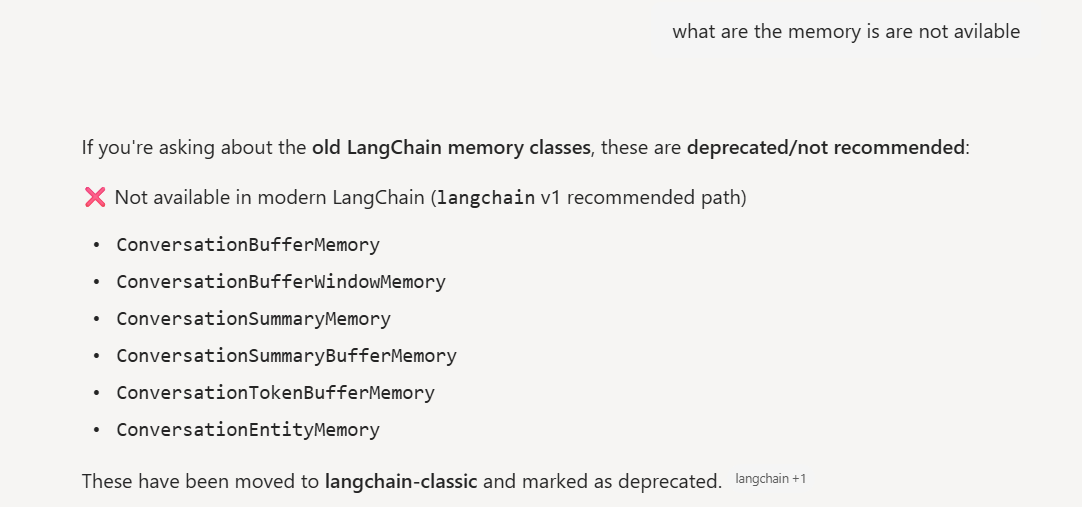

In [14]:
from IPython.display import Image, display

display(Image("Memory in LLM.png"))

#in newer version Memory are not avilable in Langchain